# Player report: Gonzalo Higuaín, Napoli, Serie A 2015/16

Scouting-style one-page report built from StatsBomb open data (events) and Transfermarkt (profile and market values, via the Kaggle dataset `davidcariboo/player-scores`).
Percentiles compare the player with every player in the same position group in the league with at least `MIN_MINUTES` minutes.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import pandas as pd

from statsbomb_tools.data import apply_per_team, load_lineups, load_events, load_matches, team_matches
from statsbomb_tools.lineups import player_appearances
from statsbomb_tools.metrics import percentiles, player_metrics, touch_locations
from statsbomb_tools.players import combine_clubs, match_log, season_stats
from player_report.colours import load_club_colours
from player_report.figure import player_report
from player_report.summary import season_summary

## Settings

In [2]:
COMPETITION_ID, SEASON_ID, LEAGUE = 12, 27, "Serie A"   # Serie A 2015/16
PLAYER_ID = 5497                                        # Gonzalo Higuaín
MIN_MINUTES = 900                                       # minimum minutes to be in the comparison group

DATA = Path("../data")
EVENTS_CACHE = DATA / "cache" / "events"
PLAYERS_CACHE = DATA / "cache" / "players"
LEAGUE_TOTALS = DATA / "cache" / f"league_{COMPETITION_ID}_{SEASON_ID}_totals.pkl"
FIGURE = Path("../figures/higuain_2015_16.png")

## League season stats

One row per player per club for the whole league, built one team at a time (a whole season of events doesn't fit comfortably in memory). The result is cached: delete `LEAGUE_TOTALS` after changing the metrics in `statsbomb_tools`.

In [3]:
matches = load_matches(COMPETITION_ID, SEASON_ID)

if LEAGUE_TOTALS.exists():
    league = pd.read_pickle(LEAGUE_TOTALS)
else:
    league = apply_per_team(matches, EVENTS_CACHE, season_stats)
    league.to_pickle(LEAGUE_TOTALS)

players = combine_clubs(league)   # one row per player, also for players who changed club
print(f"{len(matches)} matches, {league['team'].nunique()} teams, {len(players)} players")
print("Unmapped positions:", players["position_group"].isna().sum())

380 matches, 20 teams, 551 players
Unmapped positions: 0


## Comparison group, per-90 metrics and percentiles

In [4]:
player = players.loc[PLAYER_ID]
peers = players[(players["position_group"] == player["position_group"]) & (players["minutes"] >= MIN_MINUTES)]
peer_label = f"{LEAGUE} {player['position_group'].lower()}s, min. {MIN_MINUTES} minutes"

metrics = player_metrics(peers)
pct = percentiles(metrics)

print(f"{player['player']} ({player['team']}, {player['position']}) vs. {len(peers)} {peer_label}")
pd.DataFrame({"value": metrics.loc[PLAYER_ID], "percentile": pct.loc[PLAYER_ID]}).round(2)

Gonzalo Gerardo Higuaín (Napoli, Center Forward) vs. 50 Serie A strikers, min. 900 minutes


,value,percentile
np_goals,0.98,100.0
npxg,0.67,100.0
np_shots,5.32,100.0
assists,0.06,22.0
xa,0.07,38.0
key_passes,1.45,78.0
box_receptions,4.28,98.0
successful_dribbles,1.16,74.0
progressive_passes,1.75,74.0
progressive_carries,2.88,78.0


## The player's season

Match log and touches come from his main club's events (the club where he played most minutes); the lineup of his first appearance gives nickname, nationality and shirt number.

In [5]:
team = player["team"]
team_id = int(player["team_id"])
club_matches = team_matches(matches, team_id)
events = load_events(club_matches["match_id"], EVENTS_CACHE)

log = match_log(events, team_id, PLAYER_ID, club_matches)
touches = touch_locations(events, PLAYER_ID)

apps = player_appearances(events, team_id)
first_match_id = apps.loc[apps["player_id"] == PLAYER_ID, "match_id"].iloc[0]
lineup = load_lineups(first_match_id)[team]
sb_player = lineup[lineup["player_id"] == PLAYER_ID].iloc[0]

summary = season_summary(player, sb_player, team=team, league=LEAGUE, cache_dir=PLAYERS_CACHE)
summary

38/38 matches loaded


{'name': 'Gonzalo Higuaín',
 'shirt_name': 'HIGUAÍN',
 'jersey_number': 9,
 'team': 'Napoli',
 'league': 'Serie A',
 'position': 'Center Forward',
 'nationality': 'Argentina',
 'date_of_birth': '1987-12-10',
 'age': 28,
 'foot': 'right',
 'value_start': {'date': '2015-07-01', 'eur': 43000000},
 'value_end': {'date': '2016-07-15', 'eur': 65000000},
 'value_change': 0.5116279069767442,
 'appearances': 35,
 'starts': 35,
 'minutes': 3031,
 'goals': 36,
 'penalty_goals': 3,
 'assists': 2}

## Report

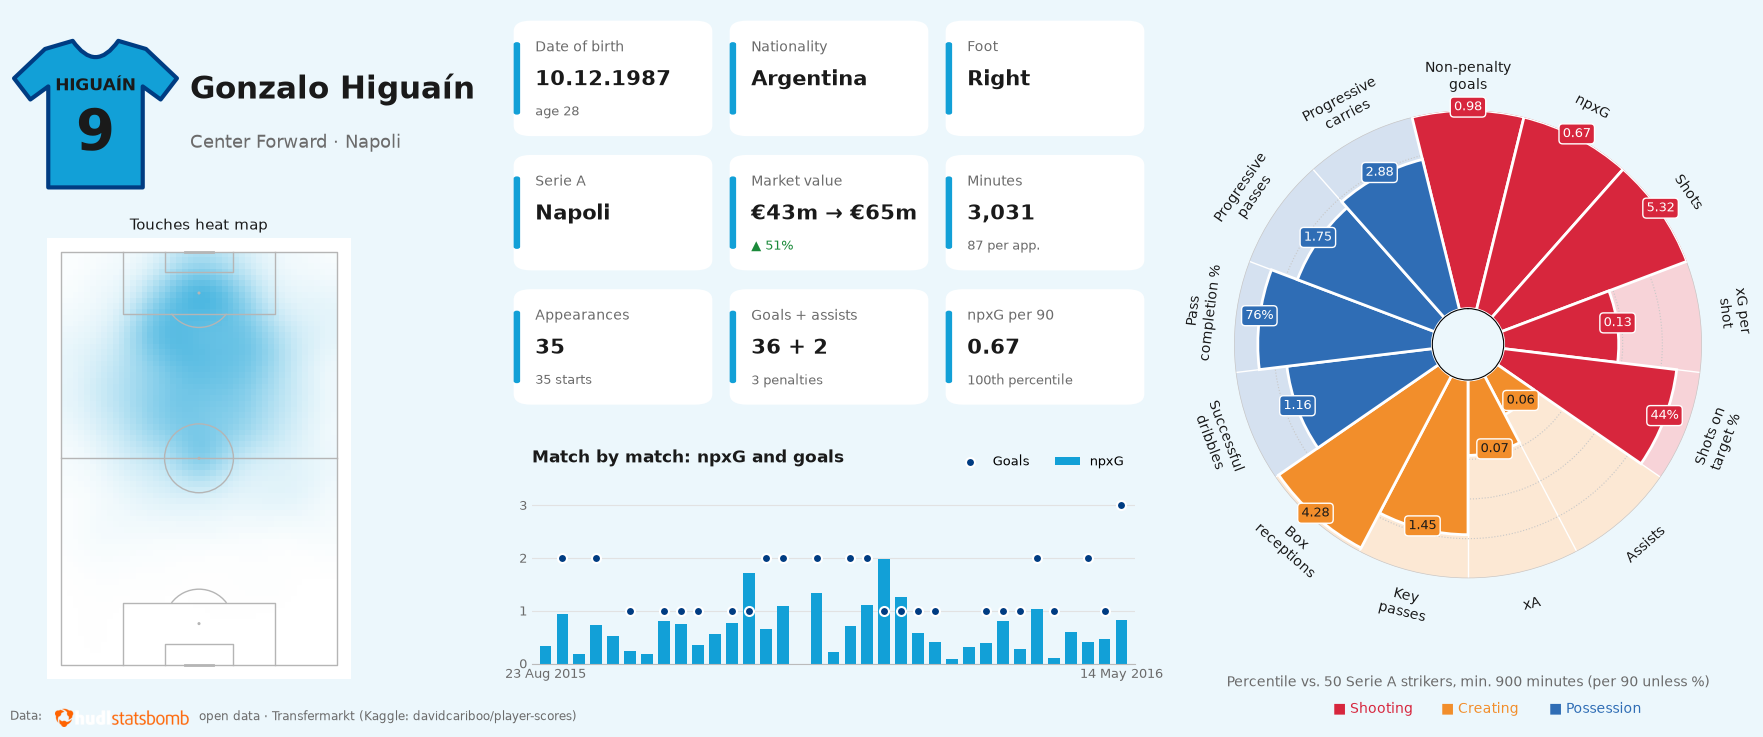

In [7]:
fig = player_report(
    summary, metrics.loc[PLAYER_ID], pct.loc[PLAYER_ID],
    n_peers=len(peers), peer_label=peer_label,
    log=log, touches=touches,
        colours=load_club_colours(DATA / "club_colours.csv").loc[team],
    logo=Path("../assets/statsbomb-logo.png"),
)
FIGURE.parent.mkdir(exist_ok=True)
fig.savefig(FIGURE, dpi=150, facecolor=fig.get_facecolor())